# 12 · Excitatory/inhibitory FHN lattice with homogeneous controls
## Goal
Place notebook 11's validated synaptic rule on a fixed nearest-neighbor square lattice. Compare all-E, all-I, and mixed E/I source assignments while holding intrinsic dynamics, graph, synaptic kinetics and initial conditions fixed. Separate global phase order, population activity and actual E/I input cancellation.

This is a deterministic dimensionless model experiment, not a physiological tissue simulation or evidence of a balanced cortical state. All computations are self-contained. Outputs are saved to `results/fhn_ei_lattice/`; NumPy, SciPy, pandas, Matplotlib and Jupyter are required. No external data or previous notebook execution is needed.

## Setup and controlled experiment
Use a 6×6 **periodic** four-neighbor lattice, spacing 1, no self-loops or diagonal neighbors. Each node has four incoming and outgoing edges. With recipients in rows and sources in columns:
$$\dot v_i=v_i-v_i^3/3-w_i+0.5+J_i^E+J_i^I,\quad \dot w_i=0.08(v_i+0.7-0.8w_i),$$
$$\dot s_j=q(v_j)(1-s_j)-0.2s_j,\quad q(v)=\mathrm{sigmoid}(v/0.1),$$
$$J_i^T=\sum_{j\in T}G_{ij}s_j(E_T-v_i),\quad G_{ij}=gA_{ij},\quad E_E=3,\ E_I=-3.$$
G is nonnegative; source type is attached to **columns/outgoing contacts**, not to the recipient's input sign. All intrinsic FHN parameters and external drive are identical. The gates are graded release, not jumps triggered by measured spikes. Initial gates are zero.

Five source assignments:
- all-E and all-I homogeneous controls;
- 18E/18I checkerboard;
- two exactly balanced 18E/18I random assignments, using assignment seeds 41 and 73.

The half-E fraction is a mathematical comparison, not a biological ratio. On this even periodic grid the checkerboard has only cross-type edges: E nodes receive I input only, and I nodes receive E input only. Random assignments allow same-type and cross-type contacts. Edge-type counts are recorded rather than inferred from population fractions.

Use per-edge g=0,0.02,0.08, with total conductance coefficient 4g at every node. E and I strengths and kinetics are equal here to isolate source assignment; equal strengths/fractions do not imply equal currents. Initial phase seeds 11 and 29 are independent of assignment seeds. The same full initial state is reused across every assignment and g for each phase seed. Five assignments × three strengths × two phase seeds = **30 lattice runs**. End time 1000; measure 400–1000 at step 0.5; spikes are positive v=0 crossings without reset. Two initial realizations do not provide a statistical ensemble or complete basin survey.

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


source        E       I     
recipient     E   I   E    I
assignment                  
all_E       144   0   0    0
all_I         0   0   0  144
checker       0  72  72    0
random_41    34  38  38   34
random_73    36  36  36   36

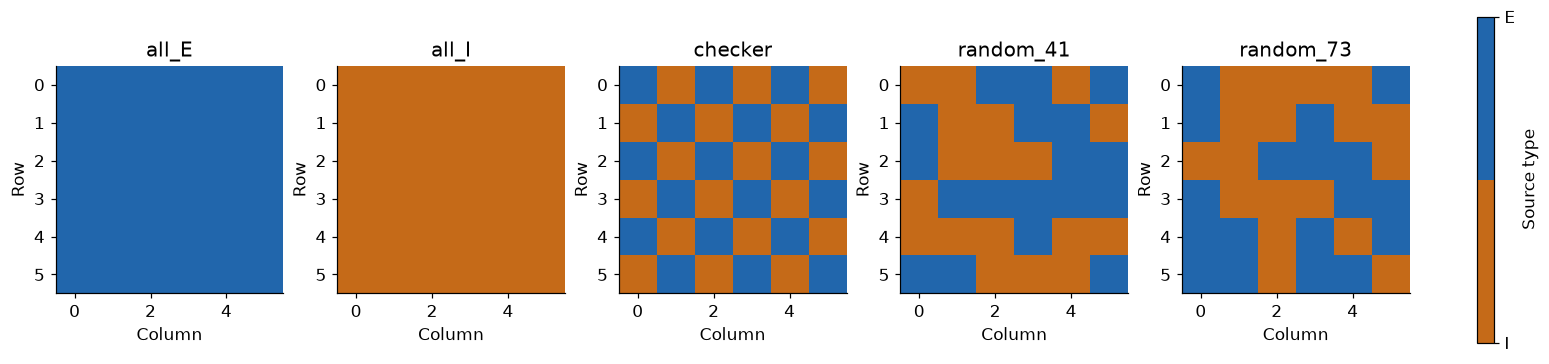

In [1]:
from pathlib import Path
import json,platform
import numpy as np
import pandas as pd
import scipy,matplotlib
from scipy.integrate import solve_ivp
from scipy.special import expit
from scipy.sparse import csr_matrix,lil_matrix
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
OUT=Path('results/fhn_ei_lattice');OUT.mkdir(parents=True,exist_ok=True)
SIDE=6;N=SIDE**2;END=1000.;BURN=400.;DT=.5
A_REC,B_REC,EPS=.7,.8,.08;ALPHA,BETA,WIDTH=1.,.2,.1
STRENGTHS=[0.,.02,.08];PHASE_SEEDS=[11,29]
BLUE,ORANGE,GRAY,OLIVE,PINK='#2166AC','#C56A18','#555555','#8A7515','#A3537B'
plt.rcParams.update({'font.size':11,'figure.dpi':110,'savefig.dpi':160,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)
print(versions)
def save(fig,name):
 fig.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show();plt.close(fig)
def adjacency(side):
 if side<3:raise ValueError('Use side >=3')
 A=np.zeros((side**2,side**2))
 for r in range(side):
  for c in range(side):
   for dr,dc in [(1,0),(-1,0),(0,1),(0,-1)]:A[r*side+c,((r+dr)%side)*side+(c+dc)%side]=1
 return A
A=adjacency(SIDE);coords=np.indices((SIDE,SIDE));checker=((coords[0]+coords[1])%2==0).ravel()
ASSIGN={'all_E':np.ones(N,dtype=bool),'all_I':np.zeros(N,dtype=bool),'checker':checker}
for seed in [41,73]:
 mask=np.zeros(N,dtype=bool);mask[np.random.default_rng(seed).choice(N,N//2,replace=False)]=True;ASSIGN[f'random_{seed}']=mask
PALETTE=dict(zip(ASSIGN,[BLUE,ORANGE,GRAY,OLIVE,PINK]))
assign_rows=[];edge_rows=[]
for name,mask in ASSIGN.items():
 for i,isE in enumerate(mask):assign_rows.append(dict(assignment=name,node=i,row=i//SIDE,column=i%SIDE,source_type='E' if isE else 'I'))
 for source_type,source_mask in [('E',mask),('I',~mask)]:
  for target_type,target_mask in [('E',mask),('I',~mask)]:
   edge_rows.append(dict(assignment=name,source=source_type,recipient=target_type,directed_contacts=int(A[np.ix_(target_mask,source_mask)].sum())))
pd.DataFrame(assign_rows).to_csv(OUT/'source_assignments.csv',index=False)
edges=pd.DataFrame(edge_rows);edges.to_csv(OUT/'edge_type_counts.csv',index=False)
display(edges.pivot(index='assignment',columns=['source','recipient'],values='directed_contacts'))
pd.DataFrame(A).to_csv(OUT/'adjacency.csv',index=False)
fig,axs=plt.subplots(1,5,figsize=(14,3.2),layout='constrained')
for ax,(name,mask) in zip(axs,ASSIGN.items()):
 im=ax.imshow(mask.reshape(SIDE,SIDE),cmap=ListedColormap([ORANGE,BLUE]),vmin=0,vmax=1)
 ax.set(title=name,xlabel='Column',ylabel='Row');ax.grid(False)
fig.colorbar(im,ax=axs.tolist(),ticks=[0,1],label='Source type').ax.set_yticklabels(['I','E'])
save(fig,'01_source_assignments')

## 1. Integrate the synaptic network
The source gate is shared across its outgoing edges because kinetics depend on that source alone. The FHN activation coordinate and reversals are not calibrated voltages. We retain notebook 11's inward-positive sign and no diffusion term. Sparse matrix products evaluate recurrent input simultaneously.

For an independent Radau reference, the analytical sparse Jacobian includes recipient driving-force derivatives, source gate derivatives, and voltage-dependent release. A finite-difference check verifies that Jacobian separately.

In [3]:
def inputs(v,s,G,E):return G@(s*E)-v*(G@s)
def rhs_values(y,currents,G,E):
 v,w,s=y.reshape(-1,3).T
 return np.column_stack((v-v**3/3-w+currents+inputs(v,s,G,E),EPS*(v+A_REC-B_REC*w),
  ALPHA*expit(v/WIDTH)*(1-s)-BETA*s)).ravel()
def jacobian(y,G,E):
 n=len(E);v,w,s=y.reshape(n,3).T;q=expit(v/WIDTH);J=lil_matrix((3*n,3*n))
 degree=G@s
 for i in range(n):
  J[3*i,3*i]=1-v[i]**2-degree[i];J[3*i,3*i+1]=-1
  J[3*i+1,3*i]=EPS;J[3*i+1,3*i+1]=-EPS*B_REC
  J[3*i+2,3*i]=ALPHA*q[i]*(1-q[i])*(1-s[i])/WIDTH
  J[3*i+2,3*i+2]=-ALPHA*q[i]-BETA
  for j in G.getrow(i).indices:J[3*i,3*j+2]=G[i,j]*(E[j]-v[i])
 return J.tocsr()
def integrate(initial,G,E,end=END,method='DOP853',rtol=1e-10,atol=1e-12):
 initial=np.asarray(initial,float);G=np.asarray(G,float);E=np.asarray(E,float);n=len(E)
 if initial.shape!=(n,3) or G.shape!=(n,n):raise ValueError('Shape mismatch')
 if not np.isfinite(initial).all() or not np.isfinite(G).all() or not np.isfinite(E).all() or np.any(G<0) or np.any(np.diag(G)!=0):raise ValueError('Invalid state or conductance')
 if np.any(initial[:,2]<0) or np.any(initial[:,2]>1):raise ValueError('Initial gate outside [0,1]')
 Gs=csr_matrix(G);events=[]
 for i in range(n):
  def event(t,y,index=i):return y[3*index]
  event.direction=1;event.terminal=False;events.append(event)
 options={}
 if method in ['Radau','BDF']:options['jac']=lambda t,y:jacobian(y,Gs,E)
 sol=solve_ivp(lambda t,y:rhs_values(y,.5,Gs,E),(0,end),initial.ravel(),method=method,
  rtol=rtol,atol=atol,events=events,dense_output=True,max_step=.25,**options)
 if not sol.success:raise RuntimeError(sol.message)
 return sol
iso=integrate([[2.,-.5,0.]],np.zeros((1,1)),np.array([3.]),end=800.,rtol=1e-10,atol=1e-12)
t0,t1=iso.t_events[0][-2:];PERIOD=t1-t0
INITIAL={};init_rows=[]
for seed in PHASE_SEEDS:
 phases=np.random.default_rng(seed).uniform(0,1,N)
 states=iso.sol(t0+phases*PERIOD).reshape(3,N).T;states[:,2]=0;INITIAL[seed]=states
 for node,(q,z) in enumerate(zip(phases,states)):init_rows.append(dict(phase_seed=seed,node=node,phase_fraction=q,v=z[0],w=z[1],s=z[2]))
pd.DataFrame(init_rows).to_csv(OUT/'initial_states.csv',index=False)
print('Reference isolated period:',PERIOD)

Reference isolated period: 39.474414980238635


## 2. Define activity, phase order and local input cancellation
For each node, retain window spike count, count frequency, period frequency and ISI CV (the latter two require at least three events). A zero count is a finite-window observation, not proof of an equilibrium. Global state spread excludes gates and is centered across all v,w states.

Event phase interpolates between consecutive positive v=0 events, without extrapolation. $R=|\langle e^{i\phi_i}\rangle_i|$ is reported for all nodes and for each nonempty E/I source population. Each uses times jointly supported by events in that particular population; valid-time fractions are saved. Missing groups or unsupported phases remain NaN. Different valid-time supports matter when comparing groups. Phases are operational event phases, not isochron phases.

Separate actual inputs $J_i^E,J_i^I$ before averaging. Define
$$C=\frac{\langle|J_i^E+J_i^I|\rangle_{i,t}}{\langle|J_i^E|+|J_i^I|\rangle_{i,t}}.$$
C=0 means exact local instantaneous cancellation in this metric; C=1 means none. Set C undefined when its denominator is zero. Taking absolute values **before averaging** prevents cancellation between different recipients from masquerading as local E/I cancellation. C alone does not establish a dynamically balanced state or capture all shunting effects. Checkerboard recipients each receive only one source type, so C=1 despite a globally mixed population (for nonzero input). Population fractions and mean signed current are insufficient balance criteria.

In [5]:
def phase_order(phase,mask):
 if not np.any(mask):return np.nan,0.
 valid=np.isfinite(phase[mask]).all(axis=0)
 if not valid.any():return np.nan,0.
 return float(np.abs(np.mean(np.exp(1j*phase[mask][:,valid]),axis=0)).mean()),float(valid.mean())
def measure(sol,mask,g,start=BURN,stop=END):
 times=np.arange(start,stop+DT/10,DT);z=sol.sol(times).reshape(N,3,-1);v,w,s=z[:,0],z[:,1],z[:,2]
 G=csr_matrix(g*A);E=np.where(mask,3.,-3.)
 JE=inputs(v,s*mask[:,None],G,E[:,None]);JI=inputs(v,s*(~mask)[:,None],G,E[:,None])
 phase=np.full((N,len(times)),np.nan);node_rows=[]
 for i,e in enumerate(sol.t_events):
  recent=e[(e>=start)&(e<=stop)];isi=np.diff(recent)
  if len(e)>=2:
   valid=(times>=e[0])&(times<=e[-1]);phase[i,valid]=np.interp(times[valid],e,2*np.pi*np.arange(len(e)))
  node_rows.append(dict(node=i,source_type='E' if mask[i] else 'I',window_spikes=len(recent),count_frequency=len(recent)/(stop-start),
   period_frequency=float(1/isi.mean()) if len(isi)>=2 else np.nan,isi_cv=float(isi.std()/isi.mean()) if len(isi)>=2 else np.nan,
   mean_E_input=float(JE[i].mean()),mean_I_input=float(JI[i].mean()),rms_E_input=float(np.sqrt(np.mean(JE[i]**2))),rms_I_input=float(np.sqrt(np.mean(JI[i]**2)))))
 nodes=pd.DataFrame(node_rows);centered=z[:,:2]-z[:,:2].mean(axis=0,keepdims=True)
 total=float(np.mean(abs(JE)+abs(JI)));C=float(np.mean(abs(JE+JI))/total) if total>1e-15 else np.nan
 row=dict(state_spread=float(np.sqrt(np.mean(np.sum(centered**2,axis=1)))),mean_count_frequency=float(nodes.count_frequency.mean()),
  std_count_frequency=float(nodes.count_frequency.std(ddof=0)),nodes_with_spikes=int((nodes.window_spikes>0).sum()),
  mean_E_input=float(JE.mean()),mean_I_input=float(JI.mean()),local_uncancelled_fraction=C,
  E_count=int(mask.sum()),I_count=int((~mask).sum()))
 for name,pop in [('all',np.ones(N,dtype=bool)),('E',mask),('I',~mask)]:
  order,coverage=phase_order(phase,pop);row[f'phase_order_{name}']=order;row[f'phase_coverage_{name}']=coverage
  row[f'count_frequency_{name}']=float(nodes.loc[pop,'count_frequency'].mean()) if pop.any() else np.nan
 return row,nodes
RUNS={};rows=[];node_tables=[];event_rows=[]
for seed in PHASE_SEEDS:
 for name,mask in ASSIGN.items():
  E=np.where(mask,3.,-3.)
  for g in STRENGTHS:
   sol=integrate(INITIAL[seed],g*A,E);RUNS[(seed,name,g)]=sol
   row,nodes=measure(sol,mask,g);rows.append(dict(phase_seed=seed,assignment=name,g=g,**row))
   nodes['phase_seed']=seed;nodes['assignment']=name;nodes['g']=g;node_tables.append(nodes)
   for node,e in enumerate(sol.t_events):event_rows.extend(dict(phase_seed=seed,assignment=name,g=g,node=node,time=float(t)) for t in e)
scan=pd.DataFrame(rows);scan.to_csv(OUT/'network_scan.csv',index=False)
node_metrics=pd.concat(node_tables,ignore_index=True);node_metrics.to_csv(OUT/'node_metrics.csv',index=False)
pd.DataFrame(event_rows).to_csv(OUT/'spike_events.csv',index=False)
display(scan[(scan.phase_seed==11)&(scan.g==.08)][['assignment','mean_count_frequency','nodes_with_spikes','phase_order_all','phase_order_E','phase_order_I','mean_E_input','mean_I_input','local_uncancelled_fraction']])
print('Completed',len(scan),'network runs.')

,assignment,mean_count_frequency,nodes_with_spikes,phase_order_all,phase_order_E,phase_order_I,mean_E_input,mean_I_input,local_uncancelled_fraction
2,all_E,0.018333,36,0.999916,0.999916,NaN,0.320002,0.000000,1.000000
5,all_I,0.021667,36,0.000004,NaN,0.000004,0.000000,-0.194042,1.000000
8,checker,0.035000,36,0.965083,1.000000,1.000000,0.105246,-0.179090,1.000000
11,random_41,0.027269,36,0.355364,0.421510,0.292872,0.174053,-0.168058,0.396576
14,random_73,0.027037,36,0.323319,0.413080,0.285175,0.173836,-0.161579,0.443762


Completed 30 network runs.


## 3. Compare controls and mixed assignments
Solid and dashed lines denote phase seeds 11 and 29. Three sampled g values are joined for comparison, not a continued bifurcation curve. Phase order measures coherent timing rather than identical state trajectories. Count frequencies have node-wise resolution 1/600; their across-node standard deviation is not a confidence interval.

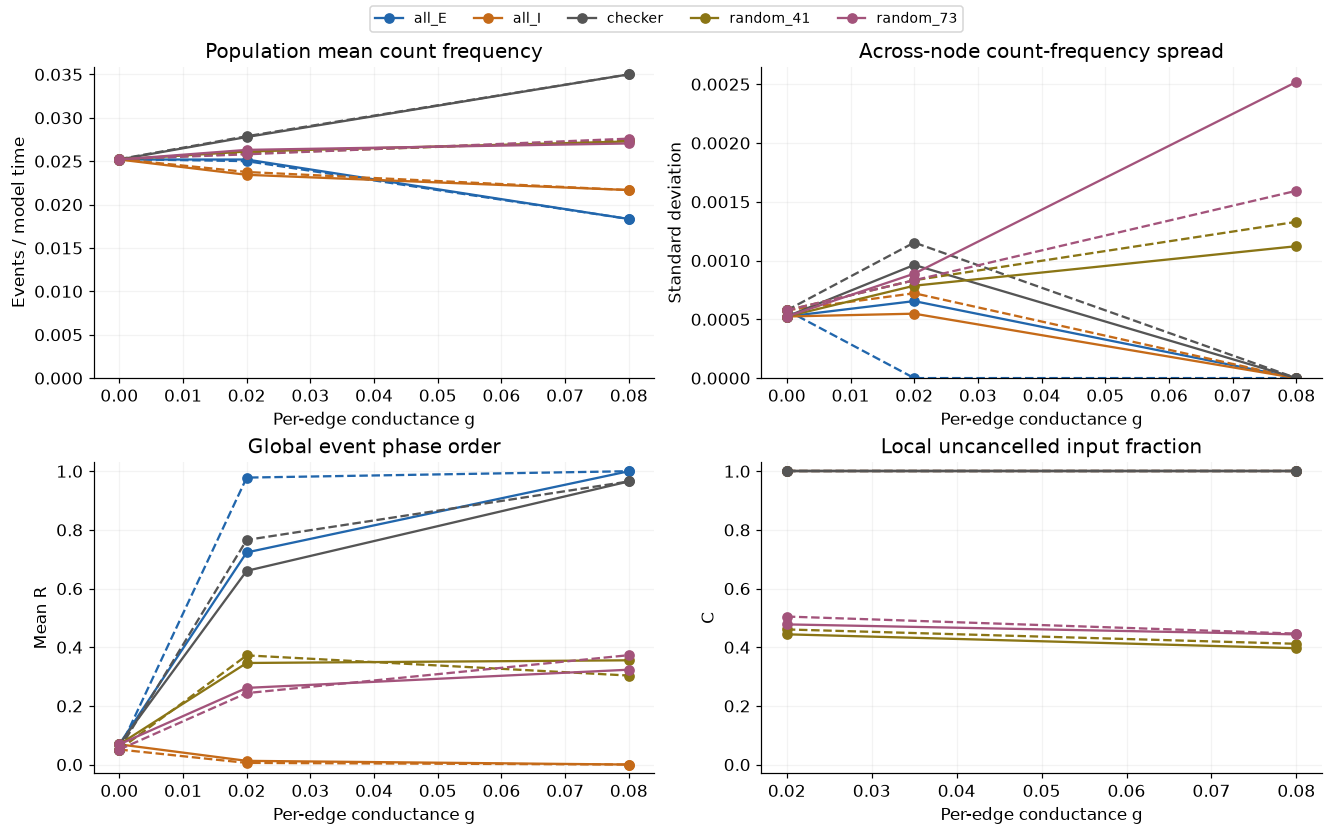

In [9]:
fig,axs=plt.subplots(2,2,figsize=(12,7.5),layout='constrained')
for name,color in PALETTE.items():
 for seed,style in [(11,'-'),(29,'--')]:
  part=scan[(scan.assignment==name)&(scan.phase_seed==seed)]
  for ax,key in zip(axs.ravel(),['mean_count_frequency','std_count_frequency','phase_order_all','local_uncancelled_fraction']):
   ax.plot(part.g,part[key],'o'+style,color=color,label=f'{name}; seed {seed}')
for ax in axs.ravel():ax.set_xlabel('Per-edge conductance g')
axs[0,0].set(title='Population mean count frequency',ylabel='Events / model time',ylim=(0,None))
axs[0,1].set(title='Across-node count-frequency spread',ylabel='Standard deviation',ylim=(0,None))
axs[1,0].set(title='Global event phase order',ylabel='Mean R',ylim=(-.03,1.03))
axs[1,1].set(title='Local uncancelled input fraction',ylabel='C',ylim=(-.03,1.03))
# One legend carries assignment colors; line styles are explained in the caption above.
handles,labels=axs[0,0].get_legend_handles_labels();fig.legend(handles[::2],[s.split(';')[0] for s in labels[::2]],loc='outside upper center',ncol=5,fontsize=9)
save(fig,'02_controls_and_mixed_scan')

## 4. Inspect spatial states and population-sorted rasters
For g=0.08 and phase seed 11, show four representative assignments. Activation snapshots share one scale. Raster rows are reordered with E sources first, then I sources; row numbers are **raster rank**, not spatial node index. The dividing line separates source types only for mixed cases. This ordering is for display and never changes the simulated graph. A nearly uniform snapshot can be synchronized oscillation rather than silence.

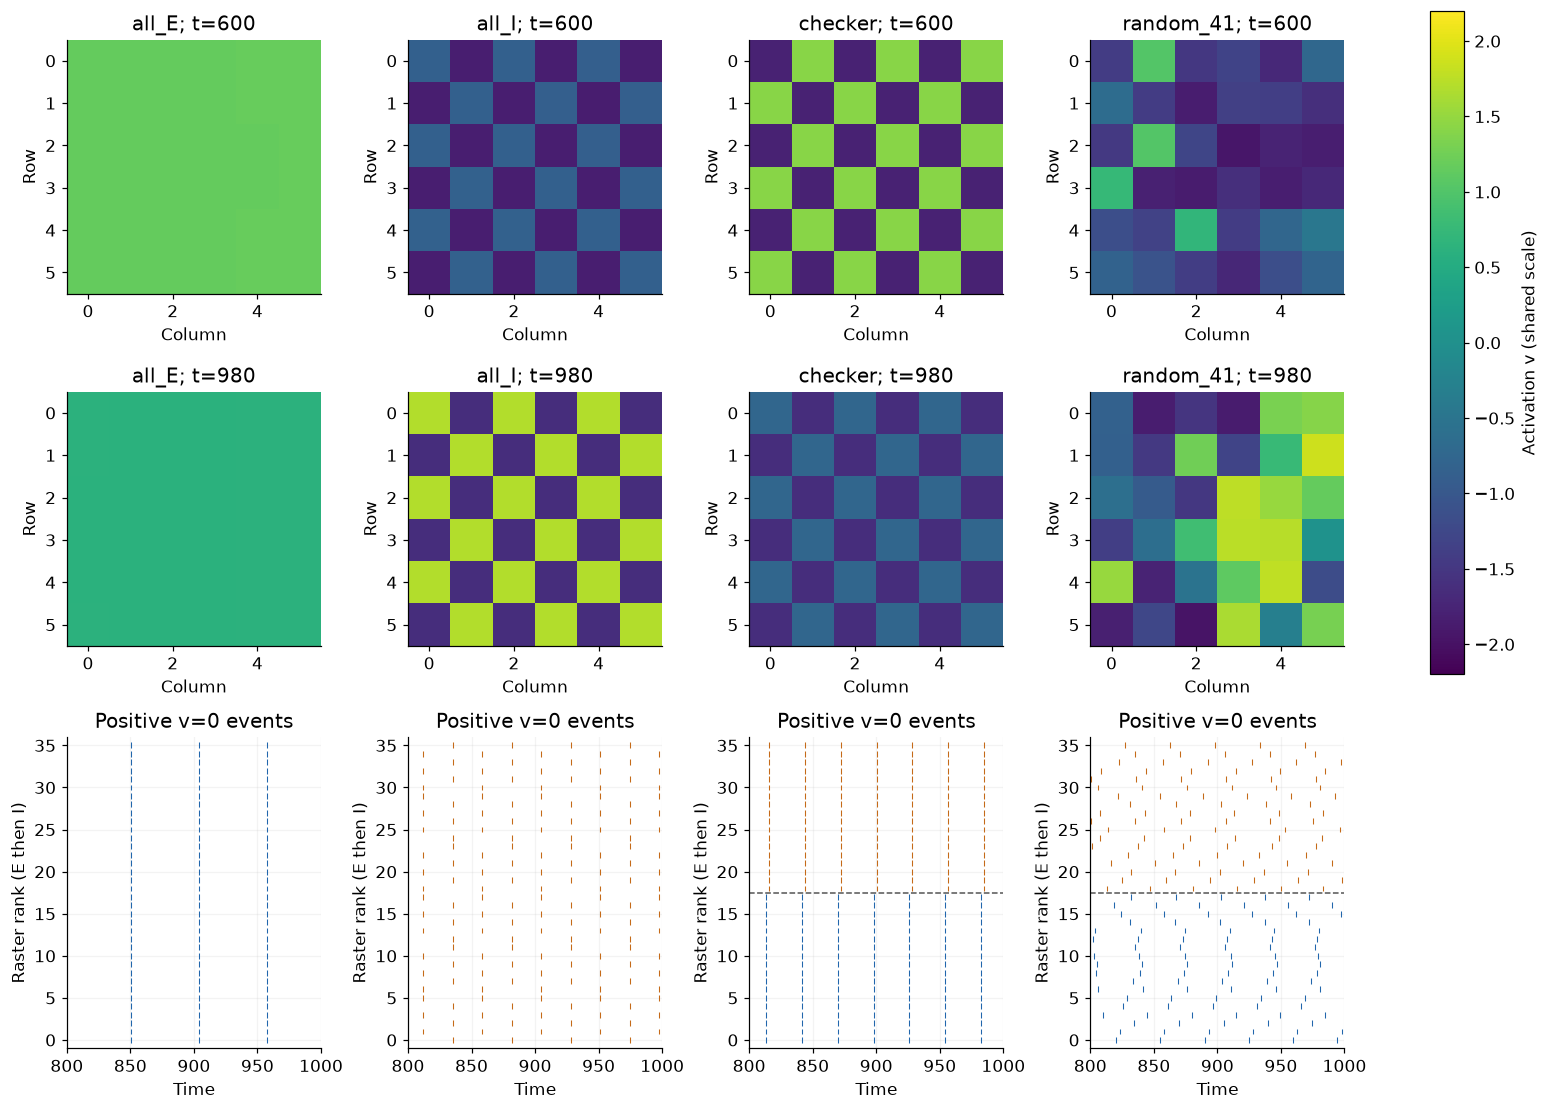

In [11]:
SHOW=['all_E','all_I','checker','random_41'];fig,axs=plt.subplots(3,4,figsize=(14,10),layout='constrained')
for col,name in enumerate(SHOW):
 mask=ASSIGN[name];sol=RUNS[(11,name,.08)]
 for row,t in enumerate([600.,980.]):
  im=axs[row,col].imshow(sol.sol(t).reshape(N,3)[:,0].reshape(SIDE,SIDE),vmin=-2.2,vmax=2.2,cmap='viridis')
  axs[row,col].set(title=f'{name}; t={t:g}',xlabel='Column',ylabel='Row');axs[row,col].grid(False)
 order=np.r_[np.flatnonzero(mask),np.flatnonzero(~mask)]
 for rank,node in enumerate(order):
  e=sol.t_events[node];e=e[(e>=800)&(e<=1000)]
  axs[2,col].vlines(e,rank-.35,rank+.35,color=BLUE if mask[node] else ORANGE,linewidth=.7)
 if mask.any() and (~mask).any():axs[2,col].axhline(mask.sum()-.5,color=GRAY,linestyle='--',linewidth=1)
 axs[2,col].set(xlabel='Time',ylabel='Raster rank (E then I)',ylim=(-1,N),xlim=(800,1000),title='Positive v=0 events')
fig.colorbar(im,ax=axs[:2,:].ravel().tolist(),label='Activation v (shared scale)')
save(fig,'03_snapshots_and_rasters')

### Diagnose the low-order all-I control
Global phase order near zero does not by itself indicate disorder. For the all-I runs at g=0.08, divide nodes by **geometric row+column parity**, independently of source type (every source is I here). Measure coherence within each parity group and their mean wrapped phase difference on common event-supported times. High group coherence with a half-cycle separation supports a two-sublattice antiphase description within the measured window, not a proof of an asymptotically stable attractor.

In [13]:
parity_rows=[]
for seed in PHASE_SEEDS:
 sol=RUNS[(seed,'all_I',.08)];tt=np.arange(BURN,END+DT/10,DT);phase=np.full((N,len(tt)),np.nan)
 for i,e in enumerate(sol.t_events):
  if len(e)>=2:
   ok=(tt>=e[0])&(tt<=e[-1]);phase[i,ok]=np.interp(tt[ok],e,2*np.pi*np.arange(len(e)))
 even_order,even_cov=phase_order(phase,checker);odd_order,odd_cov=phase_order(phase,~checker)
 valid=np.isfinite(phase).all(axis=0)
 even=np.mean(np.exp(1j*phase[checker][:,valid]),axis=0);odd=np.mean(np.exp(1j*phase[~checker][:,valid]),axis=0)
 cross=even*np.conj(odd);usable=np.abs(cross)>1e-12
 unit=cross[usable]/np.abs(cross[usable]);mean_unit=np.mean(unit)
 parity_rows.append(dict(phase_seed=seed,even_phase_order=even_order,odd_phase_order=odd_order,
  parity_lag_cycles=float(np.angle(mean_unit)/(2*np.pi)),parity_locking_value=float(abs(mean_unit)),
  common_phase_coverage=float(valid.mean())))
parity=pd.DataFrame(parity_rows);parity.to_csv(OUT/'all_I_geometric_parity.csv',index=False);display(parity)

,phase_seed,even_phase_order,odd_phase_order,parity_lag_cycles,parity_locking_value,common_phase_coverage
0,11,0.999877,0.999881,0.5,1.0,0.957535
1,29,0.999945,0.999943,-0.5,1.0,0.945878


## 5. Measure E and I inputs at the same recipient
Choose the first row-major node of random_41 that receives at least one source of each type. Plot its separate currents and activation at g=0.08, phase seed 11. The scatter compares node-wise mean E input with the magnitude of mean I input; proximity to the diagonal only describes averaged magnitudes and cannot replace the local instantaneous cancellation metric C.

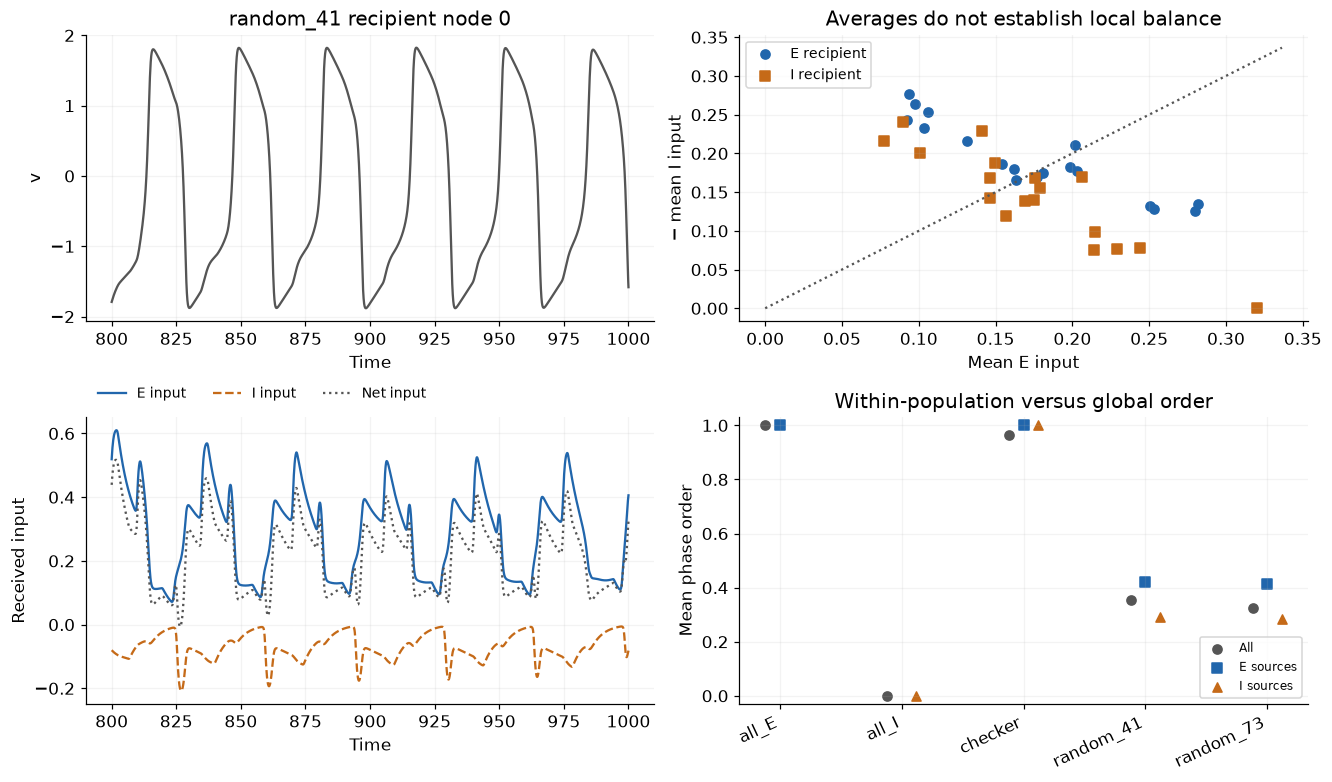

In [15]:
mask=ASSIGN['random_41'];selected=RUNS[(11,'random_41',.08)]
node=int(np.flatnonzero((A@mask.astype(float)>0)&(A@(~mask).astype(float)>0))[0])
times=np.linspace(800,1000,2001);z=selected.sol(times).reshape(N,3,-1);G=csr_matrix(.08*A);E=np.where(mask,3.,-3.)
JE=inputs(z[:,0],z[:,2]*mask[:,None],G,E[:,None]);JI=inputs(z[:,0],z[:,2]*(~mask)[:,None],G,E[:,None])
fig,axs=plt.subplots(2,2,figsize=(12,7),layout='constrained')
axs[0,0].plot(times,z[node,0],color=GRAY);axs[0,0].set(title=f'random_41 recipient node {node}',xlabel='Time',ylabel='v')
axs[1,0].plot(times,JE[node],color=BLUE,label='E input');axs[1,0].plot(times,JI[node],'--',color=ORANGE,label='I input')
axs[1,0].plot(times,JE[node]+JI[node],':',color=GRAY,label='Net input');axs[1,0].set(xlabel='Time',ylabel='Received input');axs[1,0].legend(fontsize=9,loc='upper left',bbox_to_anchor=(0,1.15),ncol=3,frameon=False)
p=node_metrics[(node_metrics.phase_seed==11)&(node_metrics.assignment=='random_41')&(node_metrics.g==.08)]
for typ,color,marker in [('E',BLUE,'o'),('I',ORANGE,'s')]:
 sub=p[p.source_type==typ];axs[0,1].scatter(sub.mean_E_input,-sub.mean_I_input,color=color,marker=marker,label=f'{typ} recipient')
edge=max(p.mean_E_input.max(),(-p.mean_I_input).max())*1.05
axs[0,1].plot([0,edge],[0,edge],':',color=GRAY);axs[0,1].set(xlabel='Mean E input',ylabel='− mean I input',title='Averages do not establish local balance');axs[0,1].legend(fontsize=9)
subset=scan[(scan.phase_seed==11)&(scan.g==.08)].set_index('assignment').loc[list(ASSIGN)]
xx=np.arange(len(ASSIGN))
for key,label,color,marker,shift in [('phase_order_all','All',GRAY,'o',-.12),('phase_order_E','E sources',BLUE,'s',0),('phase_order_I','I sources',ORANGE,'^',.12)]:
 axs[1,1].scatter(xx+shift,subset[key],label=label,color=color,marker=marker)
axs[1,1].set_xticks(xx,list(ASSIGN),rotation=25,ha='right');axs[1,1].set(ylabel='Mean phase order',ylim=(-.03,1.03),title='Within-population versus global order')
axs[1,1].legend(fontsize=8,loc='lower right')
save(fig,'04_currents_and_population_order')

## 6. Validate structure, signs and numerics
Check graph degrees, source composition, gate bounds and sampled reversal brackets. Verify the source-column current rule manually and confirm cancellation diagnostics behave differently for checkerboard and random contacts. Relabel graph, source types and initial states together to test indexing. Compare a mixed-lattice trajectory with an independent Radau solution, supported by a finite-difference Jacobian check. Extend one mixed run to inspect a later window; other parameter cuts remain finite-window measurements.

An initial rtol=10⁻⁸/atol=10⁻¹⁰ trial exceeded the preset 0.002 state-discrepancy limit against Radau (observed 0.00268515), while the event discrepancy was 0.00173846. The default is therefore tightened to rtol=10⁻¹⁰/atol=10⁻¹² for every main run, with a Radau reference at rtol=2×10⁻¹²/atol=2×10⁻¹⁴. The accuracy threshold is retained. This numerical sensitivity is not itself evidence of chaos.

,check,error,limit,passed
0,Graph symmetry,0.000000e+00,1.000000e-12,True
1,No self loops,0.000000e+00,1.000000e-12,True
2,Four neighbors per node,0.000000e+00,1.000000e-12,True
3,Exactly 72 undirected edges,0.000000e+00,5.000000e-01,True
4,checker: 18 E sources,0.000000e+00,5.000000e-01,True
5,random_41: 18 E sources,0.000000e+00,5.000000e-01,True
6,random_73: 18 E sources,0.000000e+00,5.000000e-01,True
7,Checkerboard has no same-type edges,0.000000e+00,5.000000e-01,True
8,Source-column reversal convention,2.775558e-17,1.000000e-12,True
9,Zero G independent of source assignment,0.000000e+00,1.000000e-12,True


,window,mean_count_frequency,state_spread,phase_order_all,phase_order_E,phase_order_I,local_uncancelled_fraction
0,400–1000,0.027269,1.379759,0.355364,0.421510,0.292872,0.396576
1,1400–2000,0.027222,1.388976,0.298377,0.323639,0.286458,0.408924


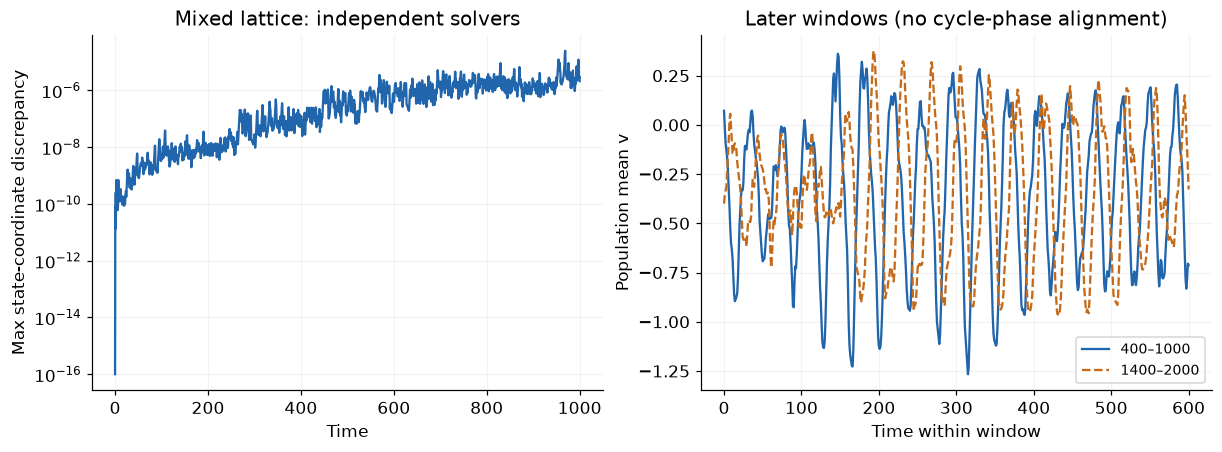

Completed 30 network runs and 20 passed checks.


In [17]:
checks=[]
def check(name,error,limit):checks.append(dict(check=name,error=float(error),limit=limit,passed=bool(error<limit)))
check('Graph symmetry',np.max(abs(A-A.T)),1e-12)
check('No self loops',np.max(abs(np.diag(A))),1e-12)
check('Four neighbors per node',np.max(abs(A.sum(axis=1)-4)),1e-12)
check('Exactly 72 undirected edges',abs(A.sum()/2-72),.5)
for name in ['checker','random_41','random_73']:check(f'{name}: 18 E sources',abs(ASSIGN[name].sum()-18),.5)
check('Checkerboard has no same-type edges',float(A[np.ix_(checker,checker)].sum()+A[np.ix_(~checker,~checker)].sum()),.5)
# Hand-computed asymmetric contact input guards recipient/source reversal placement.
v=np.array([-.5,1.]);s=np.array([.2,.7]);testG=csr_matrix([[0.,.1],[.3,0.]]);testE=np.array([3.,-3.])
check('Source-column reversal convention',np.max(abs(inputs(v,s,testG,testE)-np.array([-.175,.12]))),1e-12)
tcheck=np.linspace(0,END,2001)
check('Zero G independent of source assignment',np.max(abs(RUNS[(11,'all_E',0.)].sol(tcheck)-RUNS[(11,'all_I',0.)].sol(tcheck))),1e-12)
check('Zero G mixed assignment invariant',np.max(abs(RUNS[(11,'all_E',0.)].sol(tcheck)-RUNS[(11,'checker',0.)].sol(tcheck))),1e-12)
voltage_min=np.inf;voltage_max=-np.inf;gate_error=0.
for sol in RUNS.values():
 z=sol.sol(tcheck).reshape(N,3,-1);voltage_min=min(voltage_min,float(z[:,0].min()));voltage_max=max(voltage_max,float(z[:,0].max()))
 gate_error=max(gate_error,float(max(0.,-z[:,2].min(),z[:,2].max()-1)))
check('Sampled gates in [0,1]',gate_error,1e-8)
check('Sampled v inside reversals',max(0.,-3.-voltage_min,voltage_max-3.),1e-8)
check('E input nonnegative in observed regime',max(0.,-float(node_metrics.mean_E_input.min())),1e-10)
check('I input nonpositive in observed regime',max(0.,float(node_metrics.mean_I_input.max())),1e-10)
checker_C=scan[(scan.assignment=='checker')&(scan.g>0)].local_uncancelled_fraction
check('Checkerboard has no local E/I cancellation',np.max(abs(checker_C-1)),1e-10)
mask=ASSIGN['random_41'];E=np.where(mask,3.,-3.);G=csr_matrix(.08*A)
y=INITIAL[11].ravel().copy();y[2::3]=np.linspace(.05,.85,N)
h=1e-6;numeric=np.empty((3*N,3*N))
for j in range(3*N):
 step=np.zeros(3*N);step[j]=h
 numeric[:,j]=(rhs_values(y+step,.5,G,E)-rhs_values(y-step,.5,G,E))/(2*h)
check('Sparse Jacobian versus finite differences',np.max(abs(jacobian(y,G,E).toarray()-numeric)),2e-7)
perm=np.random.default_rng(123).permutation(N);short=np.linspace(0,100,401)
relabeled=integrate(INITIAL[11][perm],(.08*A)[np.ix_(perm,perm)],E[perm],end=100.)
check('Node relabeling covariance',np.max(abs(relabeled.sol(short).reshape(N,3,-1)-selected.sol(short).reshape(N,3,-1)[perm])),2e-5)
ref=integrate(INITIAL[11],.08*A,E,method='Radau',rtol=2e-12,atol=2e-14)
state_error=float(np.max(abs(selected.sol(tcheck)-ref.sol(tcheck))))
check('DOP853 versus Radau state convergence',state_error,2e-3)
event_error=0.
for e,er in zip(selected.t_events,ref.t_events):
 assert len(e)==len(er)
 if len(e):event_error=max(event_error,float(np.max(abs(e-er))))
check('DOP853 versus Radau event convergence',event_error,2e-3)
validation=pd.DataFrame(checks);validation.to_csv(OUT/'validation_checks.csv',index=False);display(validation)
assert validation.passed.all()
long=integrate(INITIAL[11],.08*A,E,end=2000.)
early,_=measure(selected,mask,.08);later,_=measure(long,mask,.08,1400.,2000.)
windows=pd.DataFrame([dict(window='400–1000',**early),dict(window='1400–2000',**later)])
windows.to_csv(OUT/'window_sensitivity.csv',index=False);display(windows[['window','mean_count_frequency','state_spread','phase_order_all','phase_order_E','phase_order_I','local_uncancelled_fraction']])
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axs[0].semilogy(tcheck,np.maximum(np.max(abs(selected.sol(tcheck)-ref.sol(tcheck)),axis=0),1e-16),color=BLUE)
axs[0].set(xlabel='Time',ylabel='Max state-coordinate discrepancy',title='Mixed lattice: independent solvers')
for start,stop,color,style,label in [(400.,1000.,BLUE,'-','400–1000'),(1400.,2000.,ORANGE,'--','1400–2000')]:
 tt=np.arange(start,stop+.01,1.);z=long.sol(tt).reshape(N,3,-1)
 axs[1].plot(tt-start,z[:,0].mean(axis=0),color=color,linestyle=style,label=label)
axs[1].set(xlabel='Time within window',ylabel='Population mean v',title='Later windows (no cycle-phase alignment)');axs[1].legend(fontsize=9)
save(fig,'05_numerical_and_window_checks')
summary=dict(versions=versions,side=SIDE,nodes=N,boundary='periodic',spacing=1,
 parameters=dict(a=A_REC,b=B_REC,epsilon=EPS,current=.5,alpha=ALPHA,beta=BETA,release_width=WIDTH,E_E=3,E_I=-3),
 strengths=STRENGTHS,phase_seeds=PHASE_SEEDS,assignment_seeds=[41,73],duration=END,burn=BURN,sampling_step=DT,
 solver=dict(method='DOP853',rtol=1e-10,atol=1e-12,max_step=.25),reference_solver=dict(method='Radau',rtol=2e-12,atol=2e-14),
 experiment_count=len(scan),checks_passed=int(validation.passed.sum()),state_convergence_error=state_error,event_convergence_error=event_error,
 sampled_v_range=[voltage_min,voltage_max],current_diagnostic_node=node,isolated_period=float(PERIOD))
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
print('Completed',len(scan),'network runs and',len(checks),'passed checks.')

## Next controlled extensions
1. Vary E/I source fraction, strength ratio and type assignment independently on this fixed graph, with more assignment and phase seeds. Track local currents and phase populations rather than assuming balance from a chosen ratio.
2. Transfer the same synapse to open boundaries and inverse-distance kernels, stating per-edge versus normalized coefficients and preserving the source-column convention.
3. Compare graph families at controlled size/degree/weights. Only then introduce heterogeneous intrinsic models with explicit compatible observation/input maps and shared time calibration.

### Provenance and limits
The intrinsic equations and gate rule follow project notebooks 04/11; periodic adjacency follows notebook 09. [Neuronal Dynamics §3.1](https://neuronaldynamics.epfl.ch/online/Ch3.S1.html) describes reversal-current and first-order synaptic gates; our inward-positive sign, sigmoid release and dimensionless parameters are explicitly defined above. [SciPy solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html) documents integration and event handling. These sources do not prescribe our lattice, E/I fraction or numerical parameter choices.

This notebook uses one graph size, one boundary condition, three g values and a small set of assignments/initial phases. Phase clustering, apparent low activity or finite event counts alone do not establish a stable attractor, wave, asynchronous state, chaos or physiological balance. Gates remain in [0,1] analytically; sampled numerical bounds are supplementary. Observed current signs are checked in the demonstrated activation range, not for arbitrary states beyond reversal levels. Equal fractions and equal conductances do not guarantee cancellation. No delays, synaptic plasticity, stochasticity, calibrated voltage/time, receptor-subtype differences, or distance-weighted E/I dynamics are included. The numerical-error plot uses a display floor of 10⁻¹⁶.